# SOC Market Framework -- Reproducing Baldick (2026)

This notebook runs the framework in [`Code/`](..) end to end and shows the results:
Ross Baldick's *state-of-charge based* electricity market design, reproduced on the
three numerical examples from Section 4.7 of the paper (Tables 2-4), plus a
capacity-constrained scenario beyond the paper's own examples, and a look at the
terminal value function `b(.)` that is the framework's central research object.

See [`../README.md`](../README.md) for the model in one paragraph and
[`../ROADMAP.md`](../ROADMAP.md) for the research plan this feeds into.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

# Makes the notebook runnable even without `pip install -e .` having been run first.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import plotly.colors as pcolors
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from experiments.reproduce_baldick import CASES, run_case
from terminal_value.constant import constant_willingness_to_pay
from terminal_value.piecewise_linear import piecewise_linear_bid

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4)

## Running the five cases

Each case is the same 6-interval, 4-hour-per-interval system (fixed demand, a thermal
unit at \$50/MWh, a renewable unit with time-varying available capacity, RAC) with the
ESS distinguished by its `s_max` and its constant terminal willingness-to-pay `w`; one
case also scales the whole RAC profile:

| case | `s_max` (MWh) | `w` (\$/MWh) | RAC | paper table |
|---|---:|---:|---:|---|
| `base_case` | 800 | 40 | 1x | Table 2 |
| `high_willingness_to_pay` | 800 | 55 | 1x | Table 3 |
| `increased_max_soc` | 1200 | 40 | 1x | Table 4 |
| `reduced_max_soc` | 400 | 40 | 1x | -- (not in the paper) |
| `reduced_max_soc_2x_renewable` | 400 | 40 | 2x | -- (not in the paper) |

`reduced_max_soc` halves the base case's `s_max` to see how a more capacity-constrained
("low SOC") ESS behaves -- the mirror image of `increased_max_soc`.
`reduced_max_soc_2x_renewable` keeps that same halved `s_max` but doubles renewable
availability *only in this case*, to see whether more renewable supply compensates for
less storage capacity.

`solve_day_ahead` builds and solves the ISO's welfare-maximizing LP (paper eq. 9) for
each and returns dispatch, SOC, clearing prices, and the resulting ESS surplus.

In [2]:
results = {name: run_case(name) for name in CASES}
list(results)

['base_case',
 'high_willingness_to_pay',
 'increased_max_soc',
 'reduced_max_soc',
 'reduced_max_soc_2x_renewable',
 'high_willingness_to_pay_increased_SOC']

## ISO dual variables (KKT multipliers)

Alongside the primal dispatch, `solve_day_ahead` also returns the ISO's KKT duals for
the storage block (paper Eq. 8): the SOC costate $\pi_t$ -- the marginal value of
stored energy, propagated backward from the terminal bid by the Bellman-like recursion
of Eqs. 11-12 -- the tightened SOC bound duals $\bar\nu_t$/$\nu_t$ (Eqs. 6-7), and the
nodal price $\lambda_t$. `to_dual_frame()` lays these out the way Table 1 of
[`../../Literature/KKT_MCP_equilibrium_SOC_storage.pdf`](../../Literature/KKT_MCP_equilibrium_SOC_storage.pdf)
does -- the companion note that derives this KKT system in full and verifies it
numerically on this exact base case (its "Case A"): duals as rows, intervals as
columns.

$\pi_t$ and $\lambda_t$ match that table exactly. $\bar\nu_t$/$\nu_t$ can each land on
a different (but equally valid) member of a tied set of binding SOC-cap constraints
depending on the solver's vertex -- the same kind of LP degeneracy `ROADMAP.md`
documents for the primal dispatch, now showing up in the dual space instead.

## Base case (Table 2)

Willingness-to-pay \$40/MWh is *below* the thermal offer price (\$50/MWh), so the ESS
draws its SOC all the way back down to the reference `s̄_T = 0` by the end of the
horizon -- there's no benefit to holding energy back at that price.

In [3]:
r = results["base_case"]
system, _ = CASES["base_case"]
display(r.to_frame())
display(r.to_dual_frame(system))
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,322.222,0.000,0.000,22.222,800.000,0.000
5,25.000,0.000,175.000,0.000,100.000,50.000
6,0.000,75.000,25.000,0.000,0.000,50.000


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh),49.000,1.111,1.111,1.111,49.000,40.000
ν̄ -- SOC upper-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh),0.000,47.889,0.000,0.000,0.000,9.000
λ -- price ($/MWh),43.100,50.000,0.000,0.000,50.000,50.000


objective (net system cost, $): 19,448.89
terminal value b(.) ($):        0.00
ESS surplus ($):                38,311.11


## High willingness-to-pay (Table 3)

Willingness-to-pay rises to \$55/MWh, *above* the thermal offer price. Thermal
generation increases to cover demand directly, and the ESS instead keeps 500 MWh in
reserve at the end of the horizon to capture that higher off-horizon value.

In [4]:
r = results["high_willingness_to_pay"]
system, _ = CASES["high_willingness_to_pay"]
display(r.to_frame())
display(r.to_dual_frame(system))
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,322.222,0.000,0.000,22.222,800.000,0.000
5,25.000,100.000,75.000,0.000,500.000,56.000
6,0.000,100.000,0.000,0.000,500.000,56.000


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh),49.000,1.111,1.111,1.111,55.000,55.000
ν̄ -- SOC upper-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh),0.000,47.889,0.000,0.000,0.000,0.000
λ -- price ($/MWh),43.100,50.000,0.000,0.000,56.000,56.000


objective (net system cost, $): 16,448.89
terminal value b(.) ($):        27,500.00
ESS surplus ($):                43,111.11


## Increased max SOC (Table 4)

Same \$40/MWh willingness-to-pay as the base case, but `s_max` raised to 1200 MWh. The
extra headroom lets the ESS absorb more otherwise-curtailed renewable energy in
interval 4 and displace thermal generation entirely after interval 2.

In [5]:
r = results["increased_max_soc"]
system, _ = CASES["increased_max_soc"]
display(r.to_frame())
display(r.to_dual_frame(system))
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,500.000,0.000,0.000,200.000,720.000,0.000
4,433.333,0.000,0.000,133.333,"1,200.000",0.000
5,25.000,0.000,175.000,0.000,500.000,41.000
6,0.000,0.000,100.000,0.000,100.000,41.000


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh),49.000,1.111,1.111,1.111,40.000,40.000
ν̄ -- SOC upper-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh),0.000,47.889,0.000,0.000,0.000,0.000
λ -- price ($/MWh),43.100,50.000,0.000,0.000,41.000,41.000


objective (net system cost, $): 1,193.33
terminal value b(.) ($):        4,000.00
ESS surplus ($):                46,666.67


## Reduced max SOC (half capacity)

Same \$40/MWh willingness-to-pay as the base case, but `s_max` halved to 400 MWh -- a
"low SOC" ESS with much less room to shift energy across the horizon. The SOC trajectory
hits its (lower) cap already in interval 3 and stays pinned there through interval 4, so
less of intervals 3-4's abundant renewable output can be stored: total renewable
dispatch across those two intervals drops from 822.2 MW (base case) to 711.1 MW, the
rest curtailed. With less energy banked, interval 5 needs thermal at its full 100 MW cap
to help cover demand, instead of the base case's 0 MW. Net system cost roughly doubles
(\$38,604 vs. \$19,449) and ESS surplus roughly halves (\$19,156 vs. \$38,311) --
concrete costs of losing storage capacity. Strikingly, $\pi_t$ and $\lambda_t$ come out
*identical* to the base case at every interval: storage's own interior-discharge
arbitrage condition, not thermal's binding capacity, is still what pins the price even
in interval 5, where thermal is now fully loaded.

In [6]:
r = results["reduced_max_soc"]
system, _ = CASES["reduced_max_soc"]
display(r.to_frame())
display(r.to_dual_frame(system))
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,43.100
2,100.000,10.000,90.000,0.000,0.000,50.000
3,411.111,0.000,0.000,111.111,400.000,0.000
4,300.000,0.000,0.000,0.000,400.000,0.000
5,25.000,100.000,75.000,0.000,100.000,50.000
6,0.000,75.000,25.000,0.000,0.000,50.000


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh),49.000,1.111,1.111,1.111,49.000,40.000
ν̄ -- SOC upper-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh),0.000,47.889,0.000,0.000,0.000,9.000
λ -- price ($/MWh),43.100,50.000,0.000,0.000,50.000,50.000


objective (net system cost, $): 38,604.44
terminal value b(.) ($):        0.00
ESS surplus ($):                19,155.56


## Reduced max SOC, doubled renewable

Same 400 MWh `s_max` as `reduced_max_soc`, but renewable availability (RAC) doubled for
this case only. The extra supply is now so abundant that a single interval is enough to
charge the (still-halved) ESS to its cap: it charges 111.1 MW in interval 1 alone --
more than the *unscaled* case ever charges in one interval -- reaches 400 MWh
immediately, and then sits flat at the cap through interval 4, unable to absorb any more
of the now even-more-abundant renewable output. Curtailment balloons as a result (only
300 of 1000 MW RAC is used in intervals 3 and 4). Because renewable stays interior (not
fully dispatched) throughout intervals 1-4, its own \$0/MWh offer sets the price there,
so $\lambda_t=0$ for four consecutive intervals -- a sharp contrast to every other case,
where interval 1 clears at \$43.1/MWh. Net system cost falls relative to
`reduced_max_soc` (\$30,844 vs. \$38,604), since abundant free renewable now covers most
of interval 5's gap directly and less thermal is dispatched (150 MW total vs. 185 MW) --
but it is still well above the base case's \$19,449: doubling renewable supply narrows
the cost of halved storage capacity, it doesn't eliminate it.

In [7]:
r = results["reduced_max_soc_2x_renewable"]
system, _ = CASES["reduced_max_soc_2x_renewable"]
display(r.to_frame())
display(r.to_dual_frame(system))
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,211.111,0.000,0.000,111.111,400.000,0.000
2,200.000,0.000,0.000,0.000,400.000,0.000
3,300.000,0.000,0.000,0.000,400.000,0.000
4,300.000,0.000,0.000,0.000,400.000,0.000
5,50.000,100.000,50.000,0.000,200.000,50.000
6,0.000,50.000,50.000,0.000,0.000,50.000


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh),1.111,1.111,1.111,1.111,49.000,40.000
ν̄ -- SOC upper-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,9.000
λ -- price ($/MWh),0.000,0.000,0.000,0.000,50.000,50.000


objective (net system cost, $): 30,844.44
terminal value b(.) ($):        0.00
ESS surplus ($):                19,155.56


In [8]:
r = results["high_willingness_to_pay_increased_SOC"]
system, _ = CASES["high_willingness_to_pay_increased_SOC"]
display(r.to_frame())
display(r.to_dual_frame(system))
print(f"objective (net system cost, $): {r.objective:,.2f}")
print(f"terminal value b(.) ($):        {r.terminal_value.sum():,.2f}")
print(f"ESS surplus ($):                {r.ess_surplus.sum():,.2f}")

,Renewable (MW),Thermal (MW),ESS discharge (MW),ESS charge (MW),SOC (MWh),Price ($/MWh)
Interval,,,,,,
1,200.000,0.000,0.000,100.000,360.000,48.500
2,100.000,100.000,0.000,0.000,360.000,56.000
3,500.000,0.000,0.000,200.000,"1,080.000",48.500
4,500.000,0.000,0.000,200.000,"1,800.000",48.500
5,25.000,100.000,75.000,0.000,"1,500.000",56.000
6,0.000,100.000,0.000,0.000,"1,500.000",56.000


Interval,1,2,3,4,5,6
π -- SOC costate ($/MWh),55.000,55.000,55.000,55.000,55.000,55.000
ν̄ -- SOC upper-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,0.000
ν -- SOC lower-bound dual ($/MWh),0.000,0.000,0.000,0.000,0.000,0.000
λ -- price ($/MWh),48.500,56.000,48.500,48.500,56.000,56.000


objective (net system cost, $): -20,200.00
terminal value b(.) ($):        82,500.00
ESS surplus ($):                0.00


## Dispatch vs. demand, by case

Renewable, thermal, and ESS discharge stacked against demand; ESS charging is shown
as a negative load. Watch the ESS absorb curtailed renewable energy in intervals 1, 3
and 4 and discharge it back in intervals 2, 5 and 6.

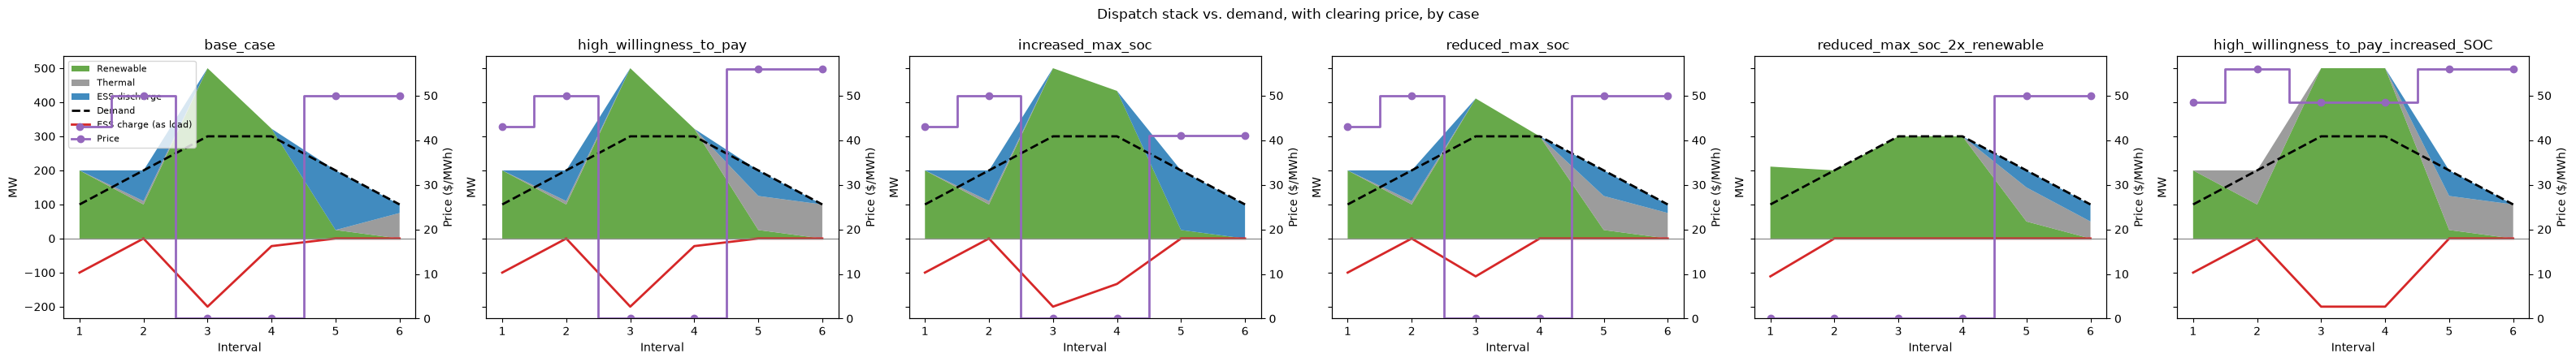

In [9]:
def plot_dispatch(name, result, ax):
    T = len(result.price)
    hours = range(1, T + 1)
    demand = [CASES[name][0].demand[t] for t in range(T)]
    discharge = result.discharge.sum(axis=0)
    charge = result.charge.sum(axis=0)

    ax.stackplot(
        hours,
        result.renewable.sum(axis=0),
        result.thermal.sum(axis=0),
        discharge,
        labels=["Renewable", "Thermal", "ESS discharge"],
        colors=["#4C9A2A", "#8B8B8B", "#1F77B4"],
        alpha=0.85,
    )
    ax.plot(hours, demand, color="black", linewidth=2, linestyle="--", label="Demand")
    ax.plot(hours, -charge, color="#D62728", linewidth=2, label="ESS charge (as load)")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Interval")
    ax.set_ylabel("MW")

    ax_price = ax.twinx()
    ax_price.step(hours, result.price, where="mid", color="#9467BD", linewidth=2, marker="o", label="Price")
    ax_price.set_ylabel("Price ($/MWh)")
    return ax_price


fig, axes = plt.subplots(1, len(CASES), figsize=(5.3 * len(CASES), 4.5), sharey=True)
price_axes = [plot_dispatch(name, results[name], ax) for ax, name in zip(axes, CASES)]

# Same price scale on every panel so the cases stay visually comparable.
price_max = max(ax.get_ylim()[1] for ax in price_axes)
for ax in price_axes:
    ax.set_ylim(0, price_max)

handles, labels = axes[0].get_legend_handles_labels()
price_handles, price_labels = price_axes[0].get_legend_handles_labels()
axes[0].legend(handles + price_handles, labels + price_labels, loc="upper left", fontsize=8)
fig.suptitle("Dispatch stack vs. demand, with clearing price, by case")
fig.tight_layout()
plt.show()

## SOC trajectories and clearing prices, compared across cases

The SOC lines make the effect of `s_max`, `w`, and RAC directly visible: the four cases
sharing the base RAC charge identically in intervals 1-2 before diverging from interval
3 onward as a higher cap, a lower cap, or a higher terminal value change what's worth
doing with the stored energy. `reduced_max_soc_2x_renewable` diverges immediately in
interval 1 instead -- doubled renewable availability is enough to charge its (halved)
cap to the max in a single interval, so its trajectory sits flat at 400 MWh from
interval 1 straight through interval 4.

In [10]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("SOC trajectory", "Clearing price"))
palette = pcolors.qualitative.Plotly

for i, (name, r) in enumerate(results.items()):
    hours = list(range(1, len(r.price) + 1))
    color = palette[i % len(palette)]

    fig.add_trace(
        go.Scatter(
            x=hours, y=r.soc.sum(axis=0), mode="lines+markers", name=name,
            legendgroup=name, line=dict(color=color),
        ),
        row=1, col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=hours, y=r.price, mode="lines+markers", name=name,
            legendgroup=name, showlegend=False, line=dict(color=color, shape="hv"),
        ),
        row=1, col=2,
    )

fig.update_xaxes(title_text="Interval", dtick=1, row=1, col=1)
fig.update_xaxes(title_text="Interval", dtick=1, row=1, col=2)
fig.update_yaxes(title_text="SOC (MWh)", row=1, col=1)
fig.update_yaxes(title_text="$/MWh", row=1, col=2)
fig.update_layout(
    height=450, width=1000,
    title_text="SOC trajectories and clearing prices, compared across cases",
    legend_title_text="case",
)
fig.show()

Interval 1's price sits at \$43.1/MWh in every case *except* `reduced_max_soc_2x_renewable`,
where doubled renewable availability leaves it interior (not fully dispatched) even
while charging the ESS to its cap, so its own \$0/MWh offer sets the price instead.
Baldick's own text describes \$43.1/MWh as the upper edge of a *range* of valid
clearing prices there, but a one-off dual-LP analysis of this exact reproduction (not
shown here, and covering only the three original paper cases -- `base_case`,
`high_willingness_to_pay`, `increased_max_soc`) found that claim doesn't hold: interval 1
comes out dual-*unique* at \$43.1/MWh, and so does the base case's interval 6
(\$50/MWh) -- only the high-willingness-to-pay case's interval 6 turns out to have a
genuine range (\$50-\$56/MWh). The two capacity-constrained cases added afterward were
not re-checked for dual uniqueness. See `ROADMAP.md`, "Price formation & dispatch
degeneracy" for the full picture, including a related but *different* fact: parts of the
*primal* dispatch are non-unique too (intervals 3-4 always, and in the base case, 5-6).

## Summary metrics across cases

In [11]:
summary = pd.DataFrame(
    {
        name: {
            "objective ($)": r.objective,
            "terminal value b(.) ($)": r.terminal_value.sum(),
            "ESS surplus ($)": r.ess_surplus.sum(),
            "terminal SOC (MWh)": r.terminal_soc.sum(),
        }
        for name, r in results.items()
    }
).T
summary

,objective ($),terminal value b(.) ($),ESS surplus ($),terminal SOC (MWh)
base_case,"19,448.889",0.000,"38,311.111",0.000
high_willingness_to_pay,"16,448.889","27,500.000","43,111.111",500.000
increased_max_soc,"1,193.333","4,000.000","46,666.667",100.000
reduced_max_soc,"38,604.444",0.000,"19,155.556",0.000
reduced_max_soc_2x_renewable,"30,844.444",0.000,"19,155.556",0.000
high_willingness_to_pay_increased_SOC,"-20,200.000","82,500.000",0.000,"1,500.000"


## The terminal value function `b(.)`

`b(delta)` is the ESS's only private input to the market -- its bid benefit for ending
the horizon `delta` MWh away from the no-participation reference `s̄_T`. The paper's own
examples use a flat marginal willingness-to-pay `w`, giving a straight-line `b`. The
framework's `piecewise_linear_bid` supports any concave shape, which is the building
block for ROADMAP.md's top research direction: comparing perfect-foresight, forecast,
learned, and misspecified terminal value functions under the same market mechanism.

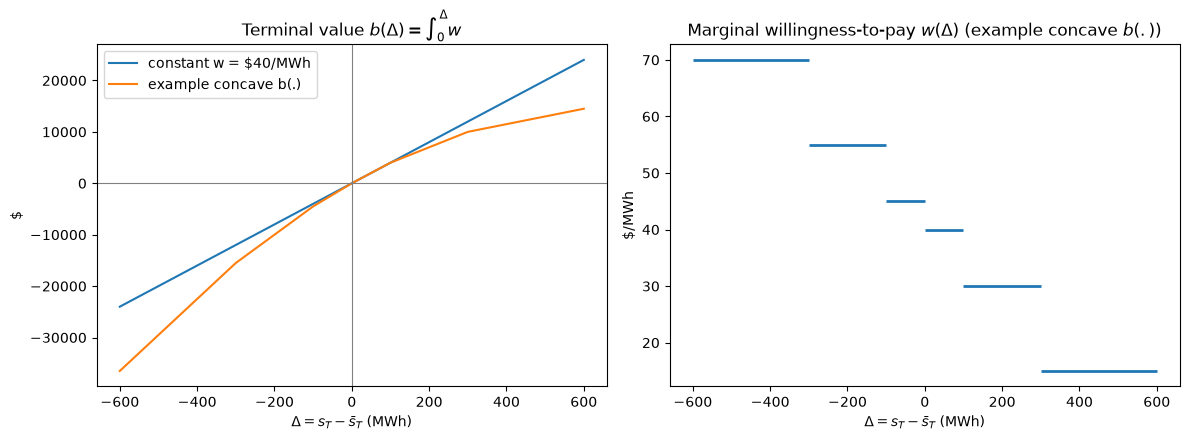

In [12]:
constant_b = constant_willingness_to_pay(w=40.0, cap=1000.0)

# An illustrative concave, two-sided b(.): marginal value falls off as the deviation
# grows in either direction, the kind of shape a learned/forecast value function might
# take -- in contrast to the flat w used in the paper's own worked examples.
example_b = piecewise_linear_bid(
    breakpoints=[-600, -300, -100, 0, 100, 300, 600],
    marginal_values=[70, 55, 45, 40, 30, 15],
)

deviations = range(-600, 601, 20)
fig, (ax_b, ax_w) = plt.subplots(1, 2, figsize=(12, 4.5))

for label, b in [("constant w = $40/MWh", constant_b), ("example concave b(.)", example_b)]:
    ax_b.plot(deviations, [b.value(d) for d in deviations], label=label)
ax_b.axhline(0, color="grey", linewidth=0.8)
ax_b.axvline(0, color="grey", linewidth=0.8)
ax_b.set_title(r"Terminal value $b(\Delta) = \int_0^\Delta w$")
ax_b.set_xlabel(r"$\Delta = s_T - \bar{s}_T$ (MWh)")
ax_b.set_ylabel("$")
ax_b.legend()

bp, mv = example_b.breakpoints, example_b.marginal_values
for k in range(len(mv)):
    ax_w.hlines(mv[k], bp[k], bp[k + 1], color="#1F77B4", linewidth=2)
ax_w.set_title(r"Marginal willingness-to-pay $w(\Delta)$ (example concave $b(.)$)")
ax_w.set_xlabel(r"$\Delta = s_T - \bar{s}_T$ (MWh)")
ax_w.set_ylabel("$/MWh")

fig.tight_layout()
plt.show()

## Next steps

This notebook exercises stage 1 of `ROADMAP.md` ("exact reproduction"). Stages 2-5 --
generalizing beyond the single-thermal/single-renewable/single-storage stylized system,
a conventional interval-bidding benchmark, uncertainty in `b(.)`, and controlled
experiments -- are not yet built. See `ROADMAP.md` for the full plan and the ranked
research directions.